### **1. Introduction:**

**What is a Decision Tree?**

Decision Tree is a Supervised learning technique that can be used for `both classification and Regression problems`, but mostly it is preferred for solving `Classification problems`. It is a tree-structured classifier, where `internal nodes` represent the features of a dataset, `branches` represent the decision rules and `each leaf` node represents the outcome.

In a Decision tree, there are two nodes, which are the `Decision Node` and `Leaf Node`. Decision nodes are used to `make any decision and have multiple branches`, whereas Leaf nodes are the `output of those decisions` and do not contain any further branches.

The decisions or the test are performed on the basis of features of the given dataset.

It is a graphical representation for getting all the possible solutions to a problem/decision based on given conditions.
It is called a decision tree because, `similar to a tree`, it starts with the `root node`, which expands on further branches and constructs a `tree-like structure`.

In order to build a tree, we use the `CART algorithm`, which stands for `Classification and Regression Tree algorithm.`

A decision tree simply asks a question, and based on the answer (Yes/No), it further split the tree into subtrees.

> ### **Solve Case Study - 1**

* Problem : A Car seats manufacturing company is interested to know about the segment or attributes causes high sale.
* Github = https://github.com/MoinDalvs/Assignment_Decision_Tree_1

**`Approach` - A decision tree can be built with target variable Sale (we will first convert it in categorical variable) & all other variable will be independent in the analysis.**

### **Step 1: Import libraries**

In [ ]:
#data handling
import numpy as np
import pandas as pd

#data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# preprocessing
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, OrdinalEncoder, StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split

#classification model
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

#hyperparameter tuning
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

#metrices
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, confusion_matrix

# Cross Validation
from sklearn.model_selection import cross_val_score

# Feature Selection
from sklearn.feature_selection import (
    RFE,f_regression,
    SelectKBest,
    VarianceThreshold, chi2)

# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV

### **Step 2: Load Dataset**

In [ ]:
df = pd.read_csv("Company_Data.csv")

### **Step 3: Understand your data**

In [ ]:
df.head()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
0,9.50,138,73,11,276,120,Bad,42,17,Yes,Yes
1,11.22,111,48,16,260,83,Good,65,10,Yes,Yes
2,10.06,113,35,10,269,80,Medium,59,12,Yes,Yes
3,7.40,117,100,4,466,97,Medium,55,14,Yes,Yes
4,4.15,141,64,3,340,128,Bad,38,13,Yes,No


In [ ]:
df.tail()

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
395,12.57,138,108,17,203,128,Good,33,14,Yes,Yes
396,6.14,139,23,3,37,120,Medium,55,11,No,Yes
397,7.41,162,26,12,368,159,Medium,40,18,Yes,Yes
398,5.94,100,79,7,284,95,Bad,50,12,Yes,Yes
399,9.71,134,37,0,27,120,Good,49,16,Yes,Yes


In [ ]:
df.sample(5)

,Sales,CompPrice,Income,Advertising,Population,Price,ShelveLoc,Age,Education,Urban,US
80,8.01,113,100,16,353,79,Bad,68,11,Yes,Yes
40,2.07,119,98,0,18,126,Bad,73,17,No,No
37,4.95,121,41,5,412,110,Medium,54,10,Yes,Yes
104,4.62,121,96,0,472,138,Medium,51,12,Yes,No
83,4.42,109,36,7,468,94,Bad,56,11,Yes,Yes


In [ ]:
print("Shape: ",df.shape)

Shape:  (400, 11)


In [ ]:
print("columns: ",df.columns)

columns:  Index(['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price',
       'ShelveLoc', 'Age', 'Education', 'Urban', 'US'],
      dtype='object')


In [ ]:
df.nunique()

,0
Sales,336
CompPrice,73
Income,98
Advertising,28
Population,275
Price,101
ShelveLoc,3
Age,56
Education,9
Urban,2


In [ ]:
df.dtypes

,0
Sales,float64
CompPrice,int64
Income,int64
Advertising,int64
Population,int64
Price,int64
ShelveLoc,object
Age,int64
Education,int64
Urban,object


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Sales        400 non-null    float64
 1   CompPrice    400 non-null    int64  
 2   Income       400 non-null    int64  
 3   Advertising  400 non-null    int64  
 4   Population   400 non-null    int64  
 5   Price        400 non-null    int64  
 6   ShelveLoc    400 non-null    object 
 7   Age          400 non-null    int64  
 8   Education    400 non-null    int64  
 9   Urban        400 non-null    object 
 10  US           400 non-null    object 
dtypes: float64(1), int64(7), object(3)
memory usage: 34.5+ KB


In [ ]:
df.describe()

,Sales,CompPrice,Income,Advertising,Population,Price,Age,Education
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,7.496325,124.975000,68.657500,6.635000,264.840000,115.795000,53.322500,13.900000
std,2.824115,15.334512,27.986037,6.650364,147.376436,23.676664,16.200297,2.620528
min,0.000000,77.000000,21.000000,0.000000,10.000000,24.000000,25.000000,10.000000
25%,5.390000,115.000000,42.750000,0.000000,139.000000,100.000000,39.750000,12.000000
50%,7.490000,125.000000,69.000000,5.000000,272.000000,117.000000,54.500000,14.000000
75%,9.320000,135.000000,91.000000,12.000000,398.500000,131.000000,66.000000,16.000000
max,16.270000,175.000000,120.000000,29.000000,509.000000,191.000000,80.000000,18.000000


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isnull().sum()

,0
Sales,0
CompPrice,0
Income,0
Advertising,0
Population,0
Price,0
ShelveLoc,0
Age,0
Education,0
Urban,0


In [ ]:
df.columns

Index(['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price',
       'ShelveLoc', 'Age', 'Education', 'Urban', 'US'],
      dtype='object')

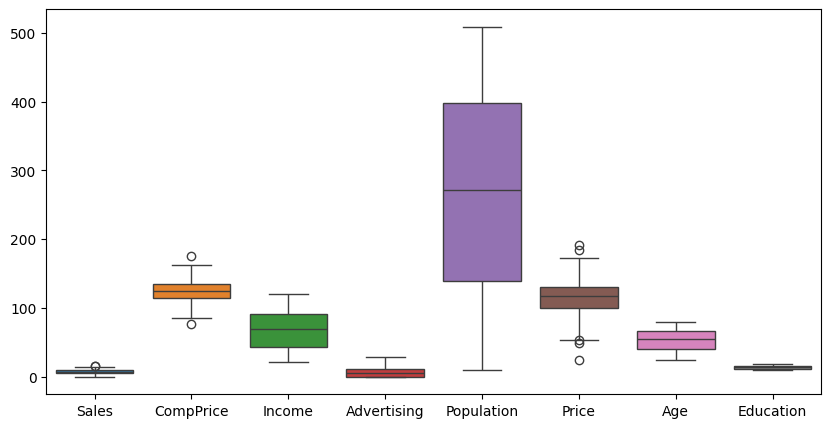

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(df[['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price', 'Age', 'Education']])
plt.show()

### **Step 4: Data Cleaning**

**remove outliers**

In [ ]:
cols = ["Sales", "CompPrice", "Price"]

for i, col in enumerate(cols, start=1):
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outliers_before = df[(df[col] < lower) | (df[col] > upper)]
    print(f"[{i}] Before capping {col}: {len(outliers_before)} outliers")

    df[col] = np.clip(df[col], a_min=lower, a_max=upper)

    outliers_after = df[(df[col] < lower) | (df[col] > upper)]
    print(f"    After capping {col}: {len(outliers_after)} outliers\n")


[1] Before capping Sales: 2 outliers
    After capping Sales: 0 outliers

[2] Before capping CompPrice: 2 outliers
    After capping CompPrice: 0 outliers

[3] Before capping Price: 5 outliers
    After capping Price: 0 outliers



**verify:**

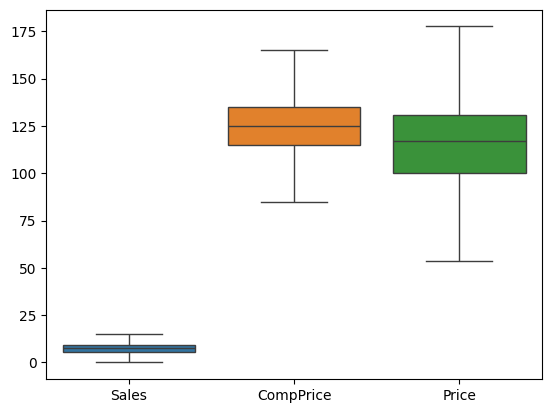

In [ ]:
sns.boxplot(df[['Sales', 'CompPrice', 'Price']])
plt.show()

### **Step 5: Data visualization**

In [ ]:
df.dtypes

,0
Sales,float64
CompPrice,int64
Income,int64
Advertising,int64
Population,int64
Price,float64
ShelveLoc,object
Age,int64
Education,int64
Urban,object


**Univariate Analysis:**

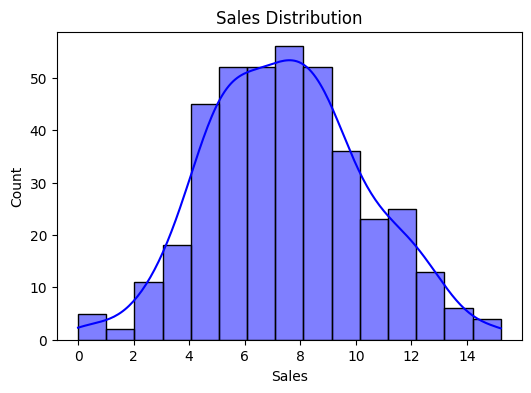

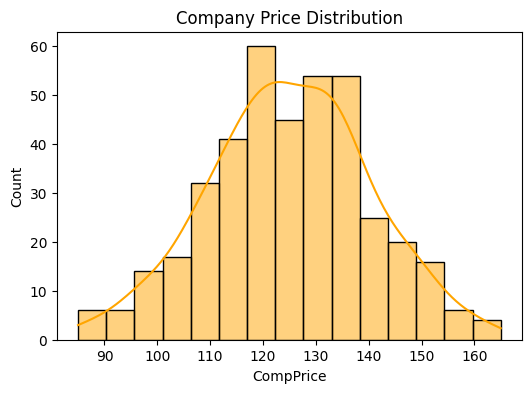

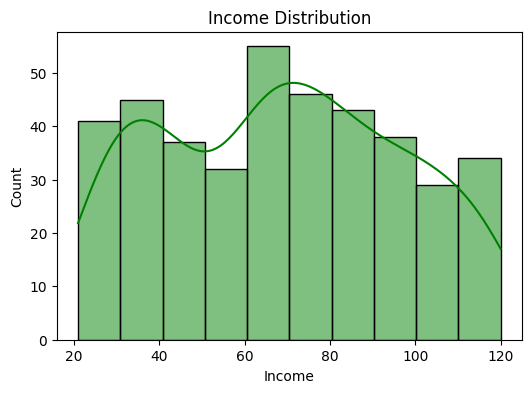

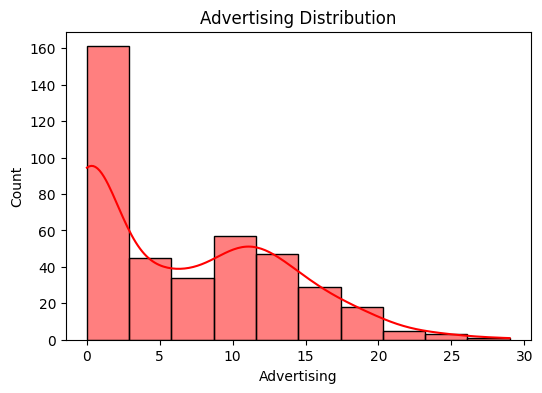

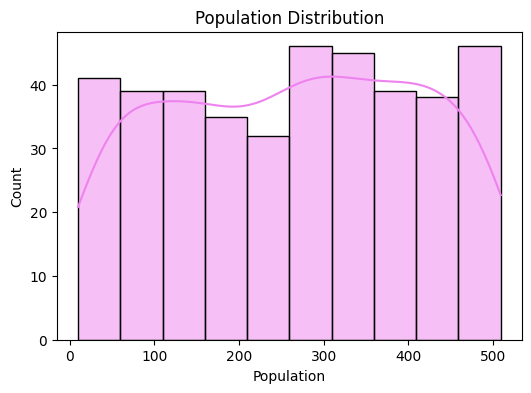

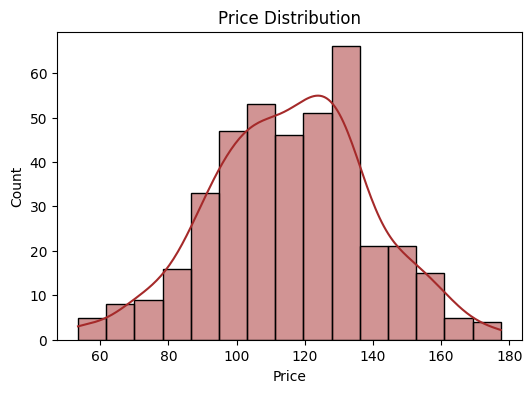

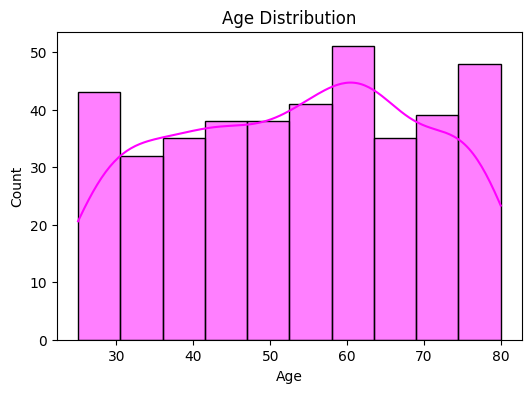

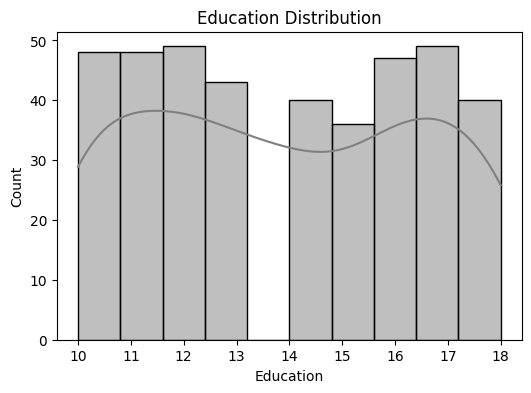

In [ ]:
plt.figure(figsize=(6, 4))
sns.histplot(df["Sales"], kde=True, color="blue")
plt.title("Sales Distribution")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df["CompPrice"], kde=True, color="orange")
plt.title("Company Price Distribution")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df["Income"], kde=True, color="green")
plt.title("Income Distribution")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df["Advertising"], kde=True, color="red")
plt.title("Advertising Distribution")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df["Population"], kde=True, color="violet")
plt.title("Population Distribution")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df["Price"], kde=True, color="brown")
plt.title("Price Distribution")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df["Age"], kde=True, color="magenta")
plt.title("Age Distribution")
plt.show()

plt.figure(figsize=(6, 4))
sns.histplot(df["Education"], kde=True, color="gray")
plt.title("Education Distribution")
plt.show()

**Bivariate Analysis:**

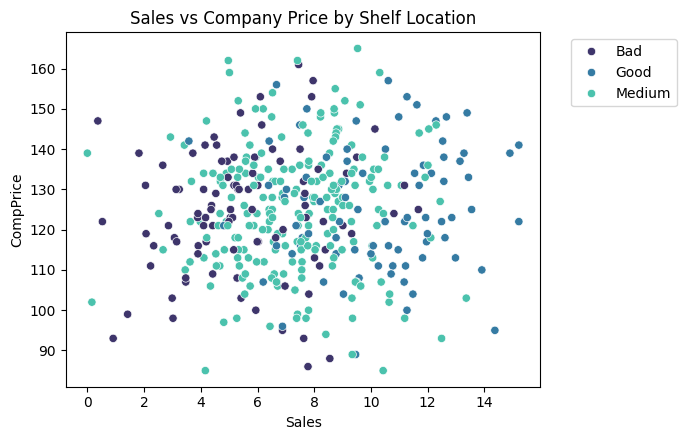

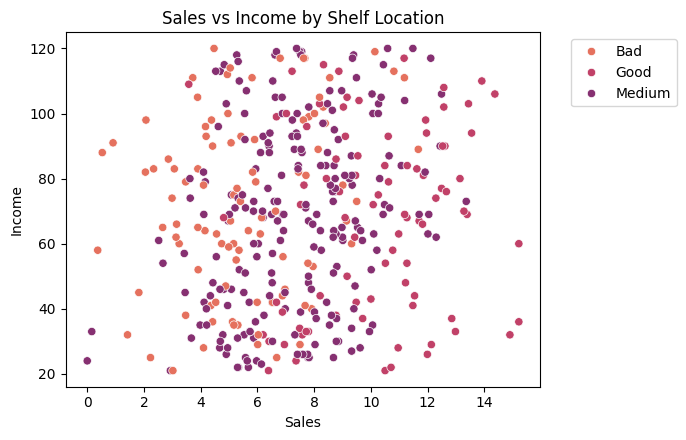

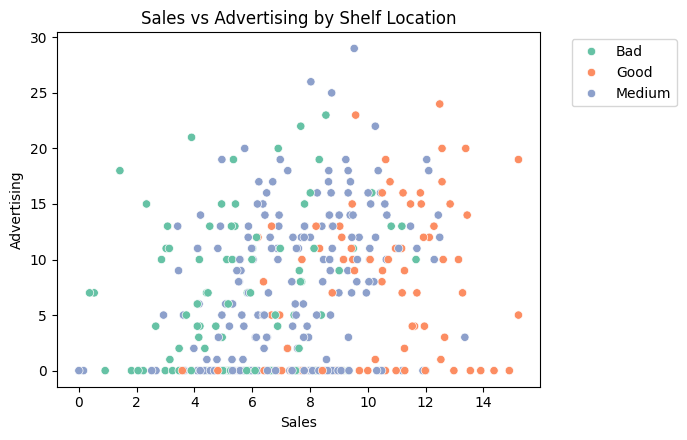

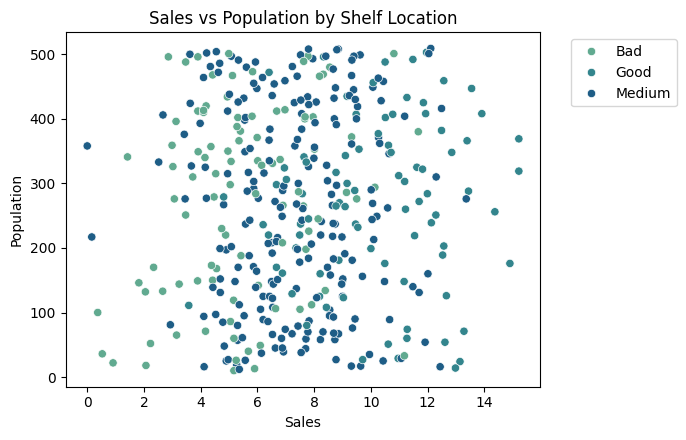

In [ ]:
# 1. Sales vs Company Price
plt.figure(figsize=(7, 4.5))
sns.scatterplot(x="Sales", y="CompPrice", data=df, hue="ShelveLoc", palette="mako")
plt.title("Sales vs Company Price by Shelf Location")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left') # Moves legend box outside the chart
plt.tight_layout()
plt.show()

# 2. Sales vs Income
plt.figure(figsize=(7, 4.5))
sns.scatterplot(x="Sales", y="Income", data=df, hue="ShelveLoc", palette="flare")
plt.title("Sales vs Income by Shelf Location")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 3. Sales vs Advertising
plt.figure(figsize=(7, 4.5))
sns.scatterplot(x="Sales", y="Advertising", data=df, hue="ShelveLoc", palette="Set2")
plt.title("Sales vs Advertising by Shelf Location")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 4. Sales vs Population
plt.figure(figsize=(7, 4.5))
sns.scatterplot(x="Sales", y="Population", data=df, hue="ShelveLoc", palette="crest")
plt.title("Sales vs Population by Shelf Location")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

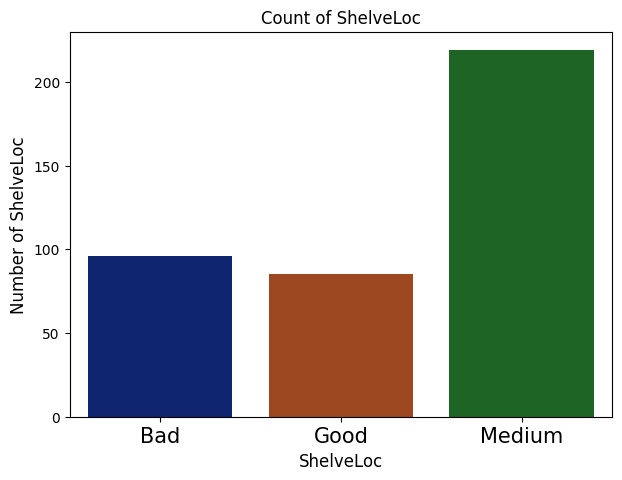

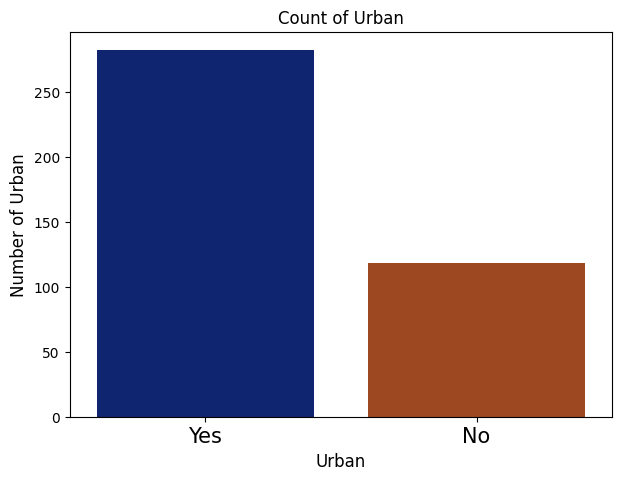

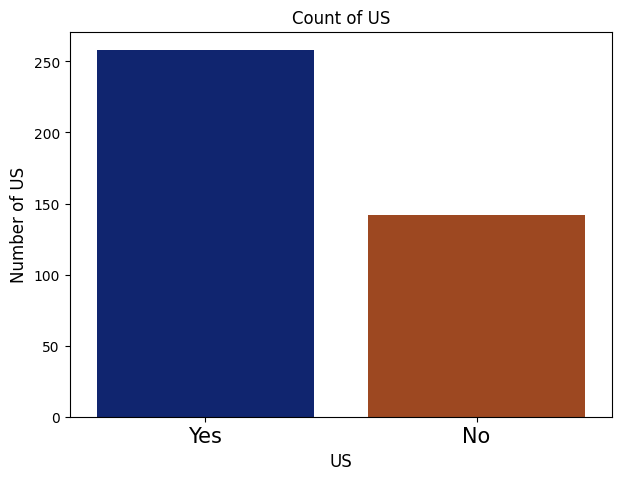

In [ ]:
cat_cols = df.select_dtypes(include=["object", "category"])

for idx, column in enumerate(cat_cols):
    plt.figure(figsize=(7, 5))
    unique = df[column].value_counts(ascending=True)

    plt.title("Count of " + column)
    sns.countplot(data=df, x=column, hue=column, palette="dark", legend=False)

    plt.xticks(rotation=0, size=15)
    plt.xlabel(column, fontsize=12)
    plt.ylabel("Number of " + column, fontsize=12)
    plt.show()

**Correlation analysis:**

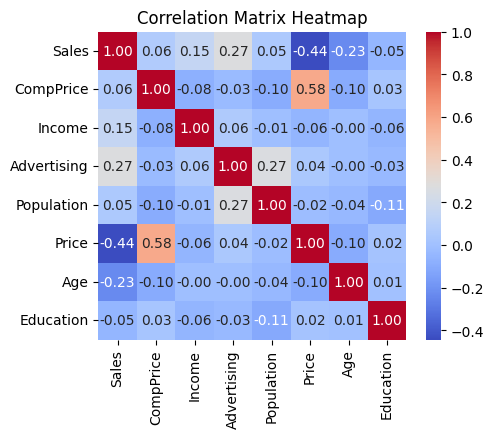

In [ ]:
numerical_cols = ['Sales', 'CompPrice', 'Income', 'Advertising', 'Population', 'Price','Age', 'Education']
corr_matrix = df[numerical_cols].corr()

plt.figure(figsize=(5,4))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Matrix Heatmap")
plt.show()

### **Step 6: Feature Engineering**

In [ ]:
df["Sales"] = pd.qcut(df["Sales"],q=3,labels=["Low", "Medium", "High"])

### **Step 8: Feature Encoding**

In [ ]:
cat_cols = ['ShelveLoc','Urban', 'US']

df = pd.get_dummies(df, columns=cat_cols, drop_first=True)

### **Step 7: Train-test-split**

In [ ]:
X = df.drop("Sales",axis=1)
y = df["Sales"]

In [ ]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

### **Step 9: Feature Scaling**

In [ ]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### **Step 10: Model Training**

In [ ]:
lr = LogisticRegression()
lr.fit(X_train_scaled,y_train)

dt = DecisionTreeClassifier()
dt.fit(X_train_scaled,y_train)

knn = KNeighborsClassifier()
knn.fit(X_train_scaled,y_train)

rf = RandomForestClassifier()
rf.fit(X_train_scaled,y_train)

nb = GaussianNB()
nb.fit(X_train_scaled,y_train)

svm = SVC()
svm.fit(X_train_scaled,y_train)

SVC()

### **Step 10: Model Evaluation**

In [ ]:
y_pred_lr = lr.predict(X_test_scaled)
lr_acc = accuracy_score(y_test,y_pred_lr)
y_pred_dt = dt.predict(X_test_scaled)
dt_acc = accuracy_score(y_test,y_pred_dt)
y_pred_knn = knn.predict(X_test_scaled)
knn_acc = accuracy_score(y_test,y_pred_knn)
y_pred_rf = rf.predict(X_test_scaled)
rf_acc = accuracy_score(y_test,y_pred_rf)
y_pred_nb = nb.predict(X_test_scaled)
nb_acc = accuracy_score(y_test,y_pred_nb)
y_pred_svm = svm.predict(X_test_scaled)
svm_acc = accuracy_score(y_test,y_pred_svm)

print("Logistic Regression:")
print("Accuracy Score: ",lr_acc)
print("Confusion Matrix: \n",confusion_matrix(y_test,y_pred_lr))

print("\nDecision Tree Classifier:")
print("Accuracy Score: ",dt_acc)
print("Confusion Matrix: \n",confusion_matrix(y_test,y_pred_dt))

print("\nK-Nearest Neighbors Classifier:")
print("Accuracy Score: ",knn_acc)
print("Confusion Matrix: \n",confusion_matrix(y_test,y_pred_knn))

print("\nRandom Forest Classifier:")
print("Accuracy Score: ",rf_acc)
print("Confusion Matrix: \n",confusion_matrix(y_test,y_pred_rf))

print("\nNaive Bayes Classifier:")
print("Accuracy Score: ",nb_acc)
print("Confusion Matrix: \n",confusion_matrix(y_test,y_pred_nb))

print("\nSupport Vector Machine Classifier:")
print("Accuracy Score: ",svm_acc)
print("Confusion Matrix: \n",confusion_matrix(y_test,y_pred_svm))

Logistic Regression:
Accuracy Score:  0.7125
Confusion Matrix: 
 [[22  1  9]
 [ 0 20  5]
 [ 5  3 15]]

Decision Tree Classifier:
Accuracy Score:  0.5625
Confusion Matrix: 
 [[23  4  5]
 [ 1 13 11]
 [ 7  7  9]]

K-Nearest Neighbors Classifier:
Accuracy Score:  0.5625
Confusion Matrix: 
 [[23  3  6]
 [ 2 18  5]
 [ 8 11  4]]

Random Forest Classifier:
Accuracy Score:  0.7
Confusion Matrix: 
 [[26  3  3]
 [ 0 17  8]
 [ 7  3 13]]

Naive Bayes Classifier:
Accuracy Score:  0.5875
Confusion Matrix: 
 [[23  7  2]
 [ 1 22  2]
 [ 3 18  2]]

Support Vector Machine Classifier:
Accuracy Score:  0.65
Confusion Matrix: 
 [[22  1  9]
 [ 0 17  8]
 [ 6  4 13]]


**Model comparision:**

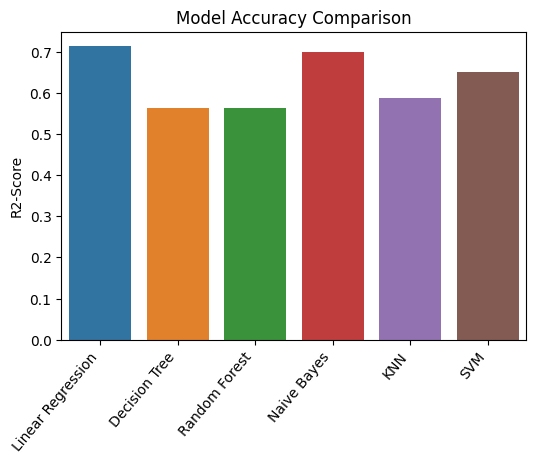

In [ ]:
r2 = [lr_acc,dt_acc,knn_acc,rf_acc,nb_acc,svm_acc]
algorithms = ["Linear Regression","Decision Tree","Random Forest","Naive Bayes","KNN","SVM"]

# accuracy score
plt.figure(figsize=(6, 4))
sns.barplot(x=algorithms,y=r2,hue=algorithms)
plt.xticks(rotation=50, ha='right')
plt.ylabel("R2-Score")
plt.title("Model Accuracy Comparison")
plt.show()

### **Step 10: Cross Validation**

In [ ]:
# 1. Logistic Regression CV
lr_cv = cross_val_score(lr, X_train_scaled, y_train, cv=5, scoring="accuracy")
print(f"Logistic Regression CV: {lr_cv.mean():.2f}%")

# 2. Decision Tree CV
dt_cv = cross_val_score(dt, X_train_scaled, y_train, cv=5, scoring="accuracy")
print(f"Decision Tree CV: {dt_cv.mean():.2f}%")

# 3. Random Forest CV
rf_cv = cross_val_score(rf, X_train_scaled, y_train, cv=5, scoring="accuracy")
print(f"Random Forest CV: {rf_cv.mean():.2f}%")

# 4. Naive Bayes
nb_cv = cross_val_score(nb, X_train_scaled, y_train, cv=5, scoring="accuracy")
print(f"Naive Bayes CV: {nb_cv.mean():.2f}%")

# 5. KNN CV
knn_cv = cross_val_score(knn, X_train_scaled, y_train, cv=5, scoring="accuracy")
print(f"KNN CV: {knn_cv.mean():.2f}%")

# 6. SVM CV
svm_cv = cross_val_score(svm, X_train_scaled, y_train, cv=5, scoring="accuracy")
print(f"SVM CV: {svm_cv.mean():.2f}%")

Logistic Regression CV: 0.76%
Decision Tree CV: 0.54%
Random Forest CV: 0.63%
Naive Bayes CV: 0.55%
KNN CV: 0.53%
SVM CV: 0.66%


### **11. Feature Selection**

In [ ]:
from sklearn.feature_selection import SelectKBest, chi2

selector = SelectKBest(score_func=chi2, k=5)
X_new = selector.fit_transform(X, y)
selected_columns = X.columns[selector.get_support()].tolist()

print(selected_columns)

['Income', 'Advertising', 'Population', 'Price', 'Age']


#### **12. Hyperparameter Tuning**

In [ ]:
grid_search = {
    "C": [30, 40, 50],
    "kernel": ['linear', 'rbf', 'poly'],
    "gamma": ['scale', 'auto']
}

gscv = GridSearchCV(svm,grid_search,cv=5,scoring='accuracy',n_jobs=-1)
gscv.fit(X_train_scaled, y_train)
print("Best parameters: ",gscv.best_params_)
print("Best Cross-Validation score: ",gscv.best_score_)

Best parameters:  {'C': 30, 'gamma': 'scale', 'kernel': 'linear'}
Best Cross-Validation score:  0.75


#### **13. Feature Importance**

In [ ]:
importance = rf.feature_importances_

for feature, score in zip(X.columns, importance):
    print(feature, round(score,2))

CompPrice 0.12
Income 0.12
Advertising 0.1
Population 0.11
Price 0.2
Age 0.12
Education 0.07
ShelveLoc_Good 0.08
ShelveLoc_Medium 0.04
Urban_Yes 0.02
US_Yes 0.01


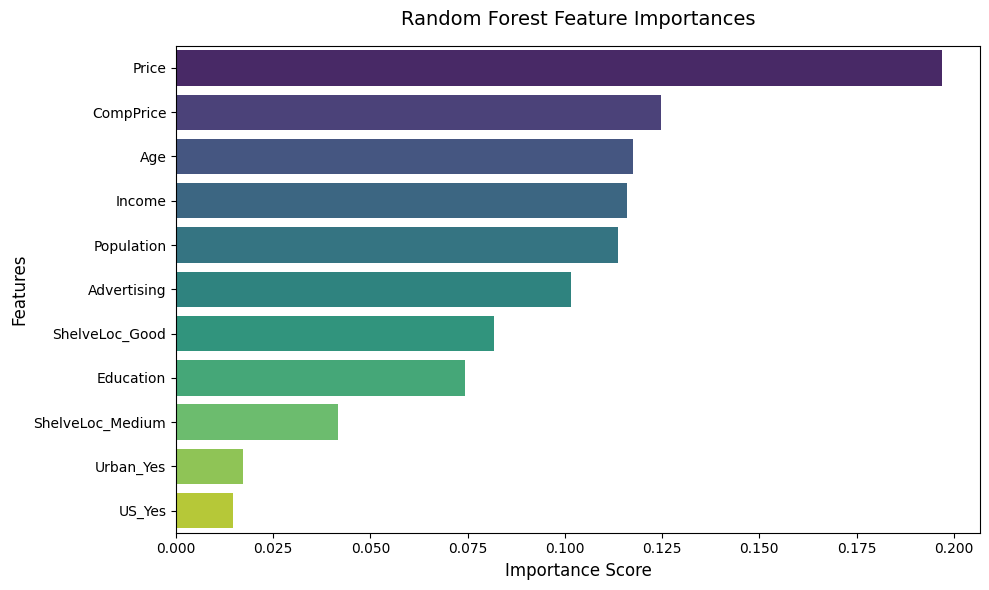

In [ ]:
df_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': rf.feature_importances_
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=df_importance, hue='Feature',legend=False, palette='viridis')
plt.title('Random Forest Feature Importances', fontsize=14, pad=15)
plt.xlabel('Importance Score', fontsize=12)
plt.ylabel('Features', fontsize=12)
plt.tight_layout()
plt.show()
